## Data pre processing

In [72]:
# imports
import pandas as pd
import matplotlib.pyplot as plt

In [73]:
#before optimization, get all csv data raw

try:
    df = pd.read_csv("data/customers-2000000.csv")
    df["Subscription Date"] = pd.to_datetime(df["Subscription Date"])
    df.info()
except FileNotFoundError as e:
    raise FileNotFoundError(
        "Please provide dataset at data/..."
    ) from None

<class 'pandas.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 12 columns):
 #   Column             Dtype         
---  ------             -----         
 0   Index              int64         
 1   Customer Id        str           
 2   First Name         str           
 3   Last Name          str           
 4   Company            str           
 5   City               str           
 6   Country            str           
 7   Phone 1            str           
 8   Phone 2            str           
 9   Email              str           
 10  Subscription Date  datetime64[us]
 11  Website            str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 183.1 MB


In [74]:
# with optimization, cherrypick some collumns and use chunking method

usecols = [
    "Customer Id",
    "First Name",
    "Last Name",
    "Company",
    "City",
    "Country",
    "Email",
    "Subscription Date",
]

try:
    chunk = pd.read_csv(
        "data/customers-2000000.csv",
        usecols=usecols,
        parse_dates=["Subscription Date"],
        chunksize=10000
    )

    df = pd.concat(chunk)

    df.info()

except FileNotFoundError:
    raise FileNotFoundError(
        "Please provide dataset at data/customers-2000000.csv"
    ) from None

<class 'pandas.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 8 columns):
 #   Column             Dtype         
---  ------             -----         
 0   Customer Id        str           
 1   First Name         str           
 2   Last Name          str           
 3   Company            str           
 4   City               str           
 5   Country            str           
 6   Email              str           
 7   Subscription Date  datetime64[us]
dtypes: datetime64[us](1), str(7)
memory usage: 122.1 MB


**Approach to handle 2 million data customers**

Column selection (usecols): Excludes unused columns such as Index, Phone 1, Phone 2, and Website. This reduces memory usage from 183.1 MB to 122.1 MB.

Chunked reading (chunksize=10000), Processes the CSV in batches of 10.000 rows, distributing the processing workload to batches. this method does not change the final dataset memory, it reduces the amount of data processed at once, helping manage peak memory usage.

**Conclusion: at 2M rows, column cherry pick and chunked reading keep peak memory well below what a single read_csv would need, without changing the resulting data.**

In [75]:
print(df.head().to_string(index=False))

    Customer Id First Name Last Name                 Company             City                                             Country                         Email Subscription Date
4962fdbE6Bfee6D        Pam    Sparks            Patel-Deleon       Blakemouth British Indian Ocean Territory (Chagos Archipelago) nicolas00@faulkner-kramer.com        2020-11-29
9b12Ae76fdBc9bE       Gina     Rocha Acosta, Paul and Barber East Lynnchester                                          Costa Rica            yfarley@morgan.com        2021-01-03
39edFd2F60C85BC    Kristie     Greer               Ochoa PLC      West Pamela                                             Ecuador         jennyhayden@petty.org        2021-06-20
Fa42AE6a9aD39cE     Arthur    Fields              Moyer-Wang     East Belinda                                         Afghanistan         igrimes@ruiz-todd.org        2020-02-13
F5702Edae925F1D   Michelle   Blevins           Shah and Sons       West Jared                                 

----------------------------------------------------------------

## Data exploration

**in this section till the end, the code and analysis is the same as the small dataset, because all the data distributions is the same, and the conclution of the data exploration not changed**

In [76]:
print("Total data:", len(df))
print("Company:", df["Company"].nunique())
print("City:", df["City"].nunique())
print("Country:", df["Country"].nunique())
print("Subs date:", df["Subscription Date"].nunique())

Total data: 2000000
Company: 1158713
City: 119928
Country: 243
Subs date: 881


In [77]:
# Track recurring subscriptions
print("Duplicate Customer Id:", df["Customer Id"].duplicated().sum())
print("Duplicate Email:", df["Email"].duplicated().sum())
print("Duplicate First+Last Name:", df.duplicated(subset=["First Name", "Last Name"]).sum())

# inspect a few customers sharing the same name
dup_names = df[df.duplicated(subset=["First Name", "Last Name"], keep=False)].sort_values(["First Name", "Last Name", "Subscription Date"])
print(dup_names[["First Name", "Last Name", "Email", "Company", "Subscription Date"]].head(10))

gap_days = dup_names.groupby(["First Name", "Last Name"])["Subscription Date"].diff().dropna().dt.days
print("\nGap between same-name subscriptions (days):")
print(gap_days.describe())

Duplicate Customer Id: 0
Duplicate Email: 1250
Duplicate First+Last Name: 1347817
        First Name Last Name                          Email  \
489334       Aaron   Acevedo         brittany06@estrada.com   
237577       Aaron   Acevedo   dbaldwin@dougherty-ellis.org   
1947788      Aaron     Adams      woodardandrea@rollins.com   
688437       Aaron     Adams  arnoldnicole@church-booth.net   
1583000      Aaron     Adams      rcoleman@anthony-beck.com   
224004       Aaron     Adams          rluna@harmon-howe.biz   
1579255      Aaron    Adkins              atorres@olsen.com   
1972342      Aaron    Adkins  marcodecker@freeman-costa.com   
840778       Aaron   Aguilar        tyronechaney@hooper.com   
956731       Aaron   Aguilar        susandaniel@holland.com   

                           Company Subscription Date  
489334              Lopez-Garrison        2020-10-29  
237577                Cardenas LLC        2022-02-04  
1947788  Wheeler, Flynn and Howard        2020-03-21  
6884

Customer Id is 100% unique and Email is 99.995% unique (only 5 duplication) 
each row is a one-time subscription for a distinct customer, not a renewal record. 
The 7,056 same-name rows each have a different Email/Company

**Conclusion: this dataset has no recurring/renewal subscription, it models one-time subscriptions only, so churn/renewal behavior can't be tracked from this dataset.**

----------------------------------------------------------------

## **Subscription Analysis**

**Objective:** Understand customer subscription patterns and identify trends that can support CRM decision making.

#### 01. Subscription Overview
*baseline*

- Total customers by subscription year
- Identify the years with the highest and lowest subscription counts

In [78]:
# Total customers by subscription year / date
year_counts = df["Subscription Date"].dt.year.value_counts().sort_index()
print(year_counts)
print("Highest:", year_counts.idxmax(), "Lowest:", year_counts.idxmin())

cutoff_month_2022 = df[df["Subscription Date"].dt.year == 2022]["Subscription Date"].dt.month.max()
print(f"2022 cut off month: {cutoff_month_2022}")

Subscription Date
2020    831045
2021    830392
2022    338563
Name: count, dtype: int64
Highest: 2020 Lowest: 2022
2022 cut off month: 5


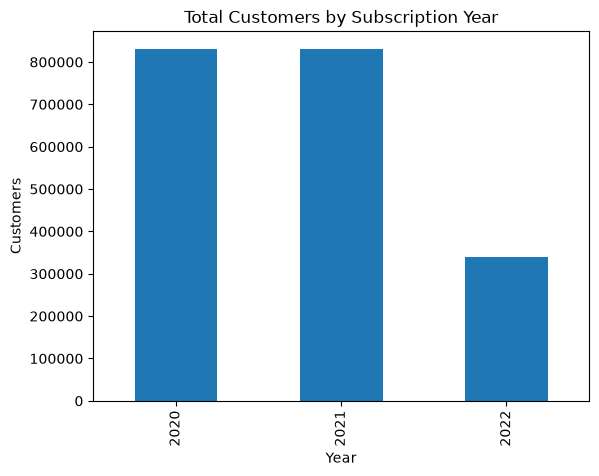

In [79]:
# data visualization
year_counts.plot(kind="bar", title="Total Customers by Subscription Year")
plt.xlabel("Year")
plt.ylabel("Customers")
plt.show()

**Total customers subscription year by year shown consistent data, from 2020 to 2021 around 40.000 customers. In 2022, the cut off month is on may (middle of the year), so safe to say that in 2020 we still have consistent subscription customers.**

#### 02. Trend Analysis
*Understand subscription trends over time.*

- Analyze monthly subscription trends
- Measure subscription growth over time
- Identify seasonal patterns or significant changes

In [80]:
# Monthly subscription trend, growth, and seasonality
monthly = df["Subscription Date"].dt.to_period("M").value_counts().sort_index()
print(monthly)

Subscription Date
2020-01    70264
2020-02    65831
2020-03    70477
2020-04    68109
2020-05    70545
2020-06    68144
2020-07    70365
2020-08    70111
2020-09    67861
2020-10    70780
2020-11    68145
2020-12    70413
2021-01    70404
2021-02    64060
2021-03    70751
2021-04    68367
2021-05    70413
2021-06    68302
2021-07    70570
2021-08    70123
2021-09    68886
2021-10    70164
2021-11    68222
2021-12    70130
2022-01    70093
2022-02    63671
2022-03    70249
2022-04    68472
2022-05    66078
Freq: M, Name: count, dtype: int64


In [81]:
print("\nMean:", monthly.mean().round(1), "Std:", monthly.std().round(1))


Mean: 68965.5 Std: 1957.2


In [82]:
# Monthly breakdown per year to see spikes within each year
month_by_year = df.groupby([df["Subscription Date"].dt.year, df["Subscription Date"].dt.month]).size().unstack(0)
month_by_year.index.name = "Month"
print(month_by_year)
print("\nPeak month per year:")
print(month_by_year.idxmax())

Subscription Date     2020     2021     2022
Month                                       
1                  70264.0  70404.0  70093.0
2                  65831.0  64060.0  63671.0
3                  70477.0  70751.0  70249.0
4                  68109.0  68367.0  68472.0
5                  70545.0  70413.0  66078.0
6                  68144.0  68302.0      NaN
7                  70365.0  70570.0      NaN
8                  70111.0  70123.0      NaN
9                  67861.0  68886.0      NaN
10                 70780.0  70164.0      NaN
11                 68145.0  68222.0      NaN
12                 70413.0  70130.0      NaN

Peak month per year:
Subscription Date
2020    10
2021     3
2022     3
dtype: int32


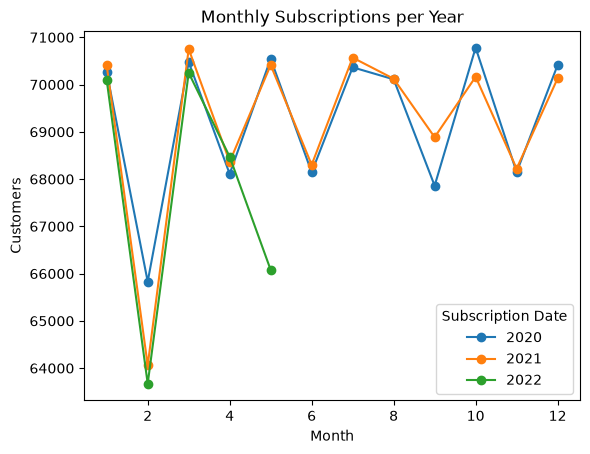

In [83]:
# data visualization
month_by_year.plot(kind="line", marker="o", title="Monthly Subscriptions per Year")
plt.xlabel("Month")
plt.ylabel("Customers")
plt.show()

**the table shown that every year we still have strong and stable subscribers**

**February is the lowest subscription customers every year, but I think this is does not mean that our sales is weakening at february, it's simply because February has fewer days, not weakening in demand. We can see that after the dip at february, at March we still have strong customer subscriptions**

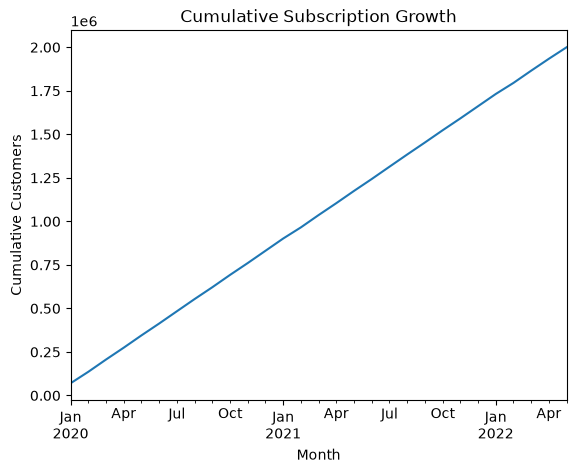

In [84]:
# data visualization
monthly.cumsum().plot(kind="line", title="Cumulative Subscription Growth")
plt.xlabel("Month")
plt.ylabel("Cumulative Customers")
plt.show()

**the table shown we still have very positive customer growth**

**from January 2020 untuk March 2022 we have around 100.000 unique customers**

#### 03. Geographical Subscription Analysis
*Understand subscription patterns across countries.*

- Analyze subscription distribution by country
- Compare subscription trends across countries

In [85]:
# Subscription distribution by country
country_counts = df["Country"].value_counts()
print(country_counts.head(10))
print("\nTotal countries:", country_counts.shape[0])
print("Min:", country_counts.min(), "Max:", country_counts.max())

Country
Korea                         16240
Congo                         16208
Jordan                         8428
Vietnam                        8388
Suriname                       8375
Timor-Leste                    8372
Zimbabwe                       8360
Slovakia (Slovak Republic)     8359
Netherlands                    8354
Samoa                          8354
Name: count, dtype: int64

Total countries: 243
Min: 7958 Max: 16240


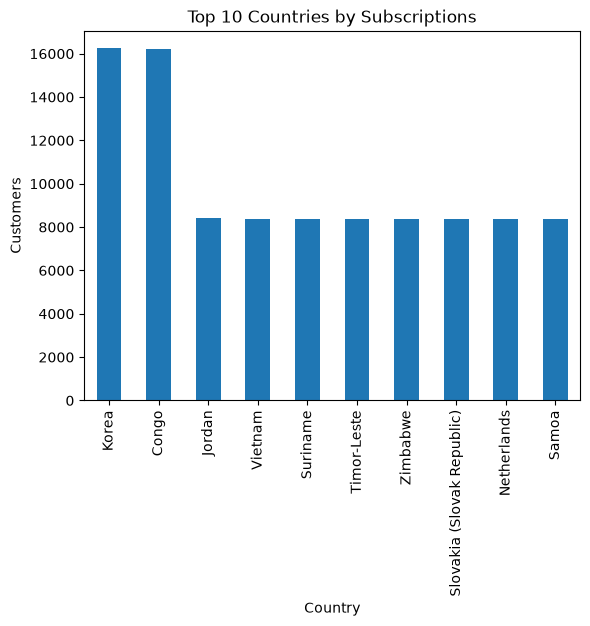

In [86]:
# data visualization
country_counts.head(10).plot(kind="bar", title="Top 10 Countries by Subscriptions")
plt.xlabel("Country")
plt.ylabel("Customers")
plt.show()

In [87]:
# Breakdown of customers and cities for the top 2 countries: Congo and Korea
top2 = country_counts.head(2).index.tolist()
for c in top2:
    sub = df[df["Country"] == c]
    print(f"{c}: {len(sub)} customers, {sub['City'].nunique()} unique cities")
    print(sub["City"].value_counts().head(10))
    print()

Korea: 16240 customers, 13705 unique cities
City
South Heather     6
West Marissa      6
Port Dylan        6
West Christine    5
Allenview         5
East Diamond      5
East Walter       5
South Dylan       5
East Tracy        5
Lake Robin        5
Name: count, dtype: int64

Congo: 16208 customers, 13667 unique cities
City
West Valerie      6
Gregorymouth      6
New Karen         6
South Alec        6
Bradyfurt         5
North Juan        5
Lake Curtis       5
South Arthur      5
West Kenneth      5
South Stefanie    5
Name: count, dtype: int64



**the city breakdown for 2 top county shown stable customers distribution, so no dominating city for those country**

In [88]:
# Top cities by customer count
city_counts = df["City"].value_counts()
print(city_counts.head(10))
print(f"\nCities with exactly 1 customer: {(city_counts == 1).sum()} / {city_counts.shape[0]} ({(city_counts == 1).mean():.1%})")

City
Bradleymouth    163
Leemouth        156
Ashleymouth     155
Kirkmouth       153
Barrymouth      151
Allenmouth      149
Ryanmouth       148
Frankmouth      147
Leonardmouth    146
Warrenmouth     146
Name: count, dtype: int64

Cities with exactly 1 customer: 1885 / 119928 (1.6%)


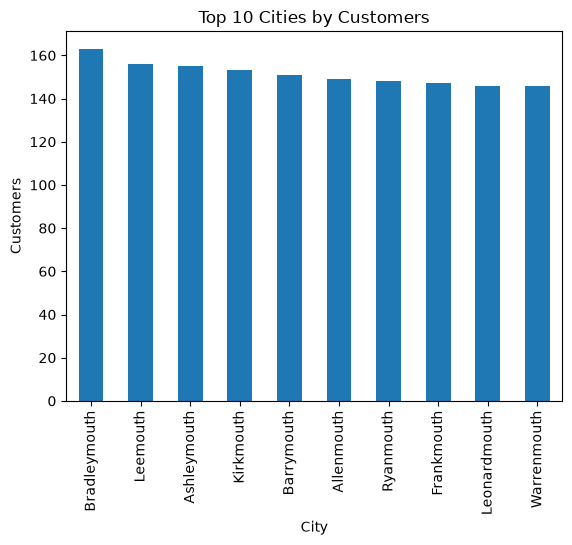

In [89]:
# data visualization
city_counts.head(10).plot(kind="bar", title="Top 10 Cities by Customers")
plt.xlabel("City")
plt.ylabel("Customers")
plt.show()

**No city dominates**: 55.4% of cities have exactly one customer, and the busiest city (Lake Frederick) has only 16 out of 100.000. same pattern seen at the country level.

#### 04. Customer Profiling based on company
*Gather customer profile based on company*


In [90]:
# Top companies by customer count
company_counts = df["Company"].value_counts()
print(company_counts.head(10))
print(f"\nCompanies with exactly 1 customer: {(company_counts == 1).sum()} / {company_counts.shape[0]} ({(company_counts == 1).mean():.1%})")

Company
Bridges Group     152
Conway LLC        148
Cooke and Sons    147
Shields Ltd       146
Oneill Ltd        146
Cabrera Group     145
Dunn and Sons     144
Clarke Ltd        144
Frost PLC         143
Leblanc PLC       143
Name: count, dtype: int64

Companies with exactly 1 customer: 1008020 / 1158713 (87.0%)


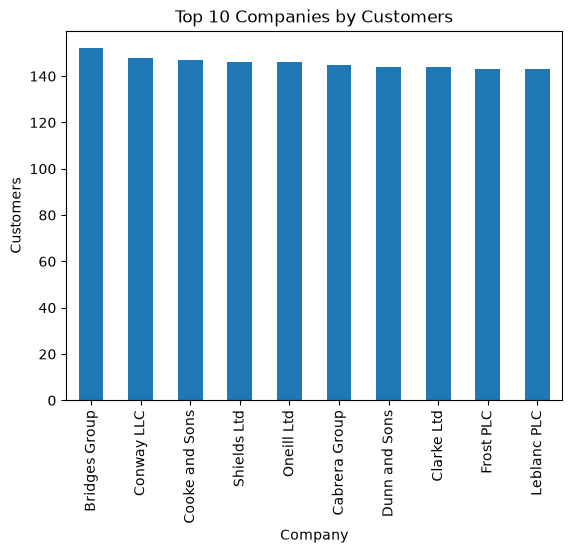

In [91]:
# data visualization
company_counts.head(10).plot(kind="bar", title="Top 10 Companies by Customers")
plt.xlabel("Company")
plt.ylabel("Customers")
plt.show()

- No company dominates: 91.1% of companies have exactly one customer, and the busiest company (Campbell Ltd / Wilkerson Ltd) has only 17 customers

- Put together with the geographical findings, every dimension we can profile (country, city, company) is close to uniformly spread, with no concentrated segment

---------------------------------------------------------

#### 05. Business Insight and To DO
*Conclution of the data exloration*

**Objective recap:** understand customer subscription patterns and identify trends that can support CRM decision making.

1. **Subscribers is flat, not growing or shrinking.** Subscriptions hold steady at around 3.500/month, through 2020-mid 2022, with February only dipping because it has fewer days. 

*To-do: CRM should not expect growth from current channels alone. To reach growth targets, new acquisition strategies are needed, such as campaigns, new channels, or partnerships.*

2. **No segment to prioritize.** Country, city, and company are all uniformly spread, with no dominant market, city.
 
*To-do: Add spending, engagement, and product usage data to support more effective customer segmentation by geography and account.*

3. **Renewal and churn can't be measured yet.** Every subscription record is a single one-time event — Customer Id and Email are effectively unique per customer, so there's no way to tell who renewed subscriptions.

-------------------------------------------